<a href="https://colab.research.google.com/github/Lorichag/VisIA/blob/main/Smart_Glasses_Obstacle_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Partie 1 : cartes de profondeurs

Installation de opencv

In [1]:
!pip install -q opencv-python-headless matplotlib pillow

In [2]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Toutes les bibliothèques sont installées !")

Toutes les bibliothèques sont installées !


Utilisation de DepthAnything

In [3]:
!git clone https://github.com/DepthAnything/Depth-Anything-V2.git

Cloning into 'Depth-Anything-V2'...
remote: Enumerating objects: 146, done.
remote: Total 146 (delta 0), reused 0 (delta 0), pack-reused 146 (from 1)
Receiving objects: 100% (146/146), 45.18 MiB | 26.59 MiB/s, done.
Resolving deltas: 100% (45/45), done.


In [4]:
%cd Depth-Anything-V2

!mkdir -p checkpoints

!wget -q https://huggingface.co/depth-anything/Depth-Anything-V2-Small/resolve/main/depth_anything_v2_vits.pth -O checkpoints/depth_anything_v2_vits.pth

/content/Depth-Anything-V2


In [5]:
import torch
from depth_anything_v2.dpt import DepthAnythingV2

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

model_config = {
    "encoder": "vits",
    "features": 64,
    "out_channels": [48, 96, 192, 384]
}

model = DepthAnythingV2(**model_config)

checkpoint = torch.load(
    "checkpoints/depth_anything_v2_vits.pth",
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint)

model = model.to(DEVICE)
model.eval()

print("Modèle chargé sur :", DEVICE)

Modèle chargé sur : cpu


Premier test sur une image

Saving rue.jpg to rue.jpg


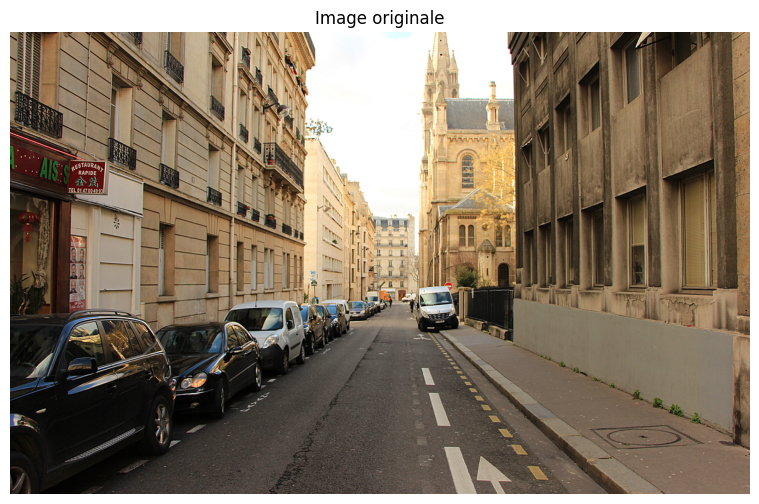

In [6]:
from google.colab import files
import cv2
import matplotlib.pyplot as plt

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(image_rgb)
plt.title("Image originale")
plt.axis("off")
plt.show()

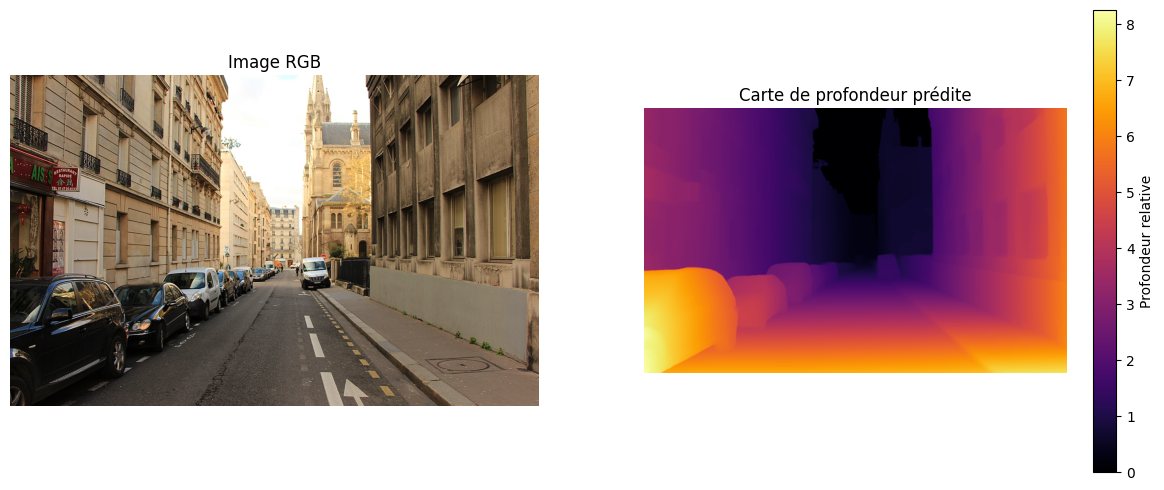

In [10]:
depth = model.infer_image(image)

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Image RGB")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(depth, cmap="inferno")
plt.title("Carte de profondeur prédite")
plt.colorbar(label="Profondeur relative")
plt.axis("off")

plt.show()

In [13]:
import numpy as np

np.save("/content/depth_map.npy", depth)

print("Carte de profondeur sauvegardée !")

Carte de profondeur sauvegardée !


Second test avec une vidéo

In [7]:
from google.colab import files

uploaded_video = files.upload()

video_path = next(iter(uploaded_video.keys()))

print("Vidéo chargée :", video_path)

Saving VID_20261118_102513.mp4 to VID_20261118_102513.mp4
Vidéo chargée : VID_20261118_102513.mp4


FPS : 29.991816292001957
Nombre total d'images : 441
Durée : 14.704011111111111 secondes


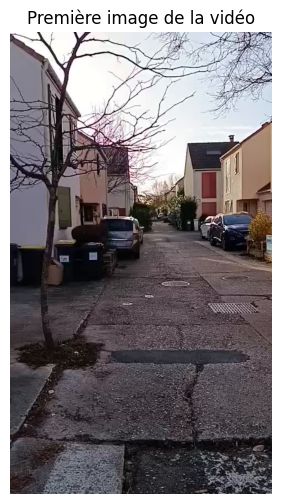

In [8]:
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print("FPS :", fps)
print("Nombre total d'images :", total_frames)
print("Durée :", total_frames / fps, "secondes")

ret, frame = cap.read()

if ret:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(frame_rgb)
    plt.title("Première image de la vidéo")
    plt.axis("off")
    plt.show()

cap.release()

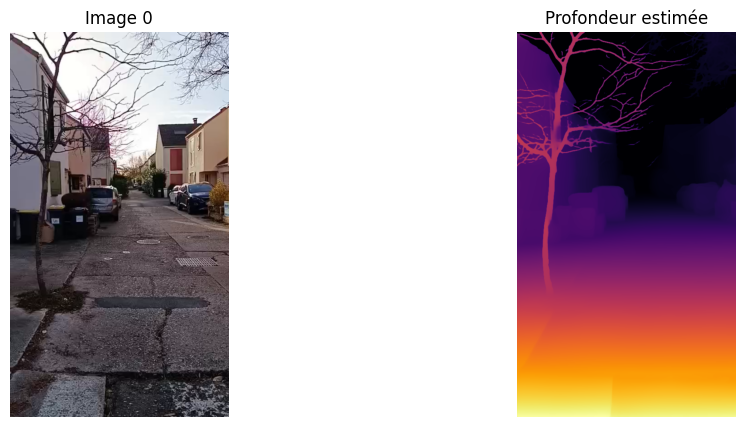

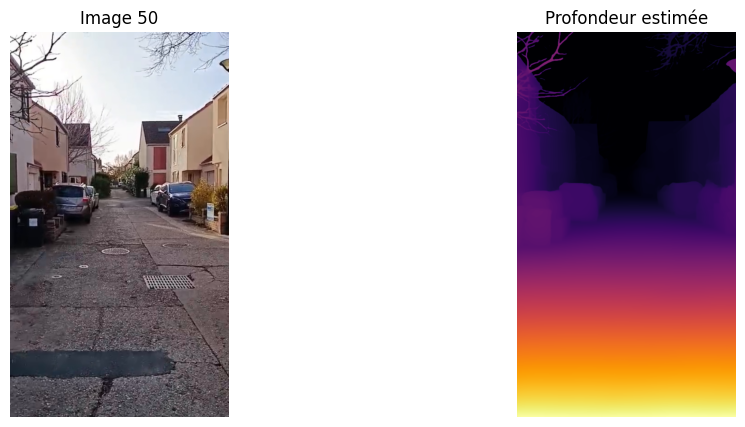

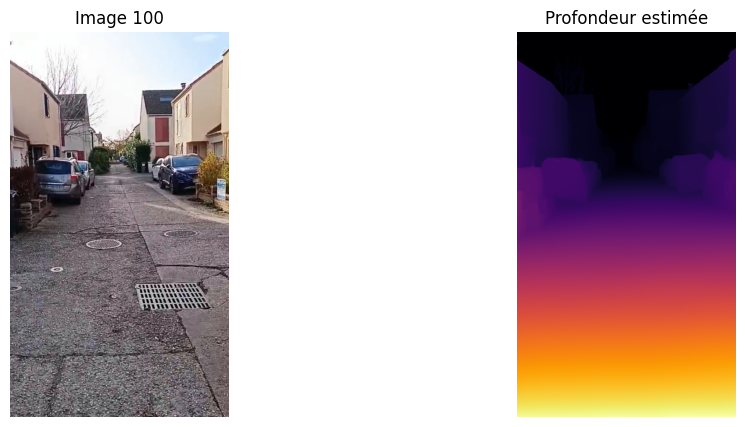

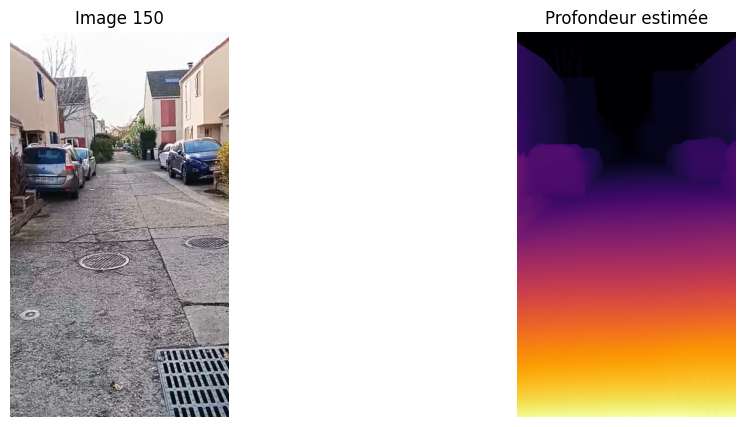

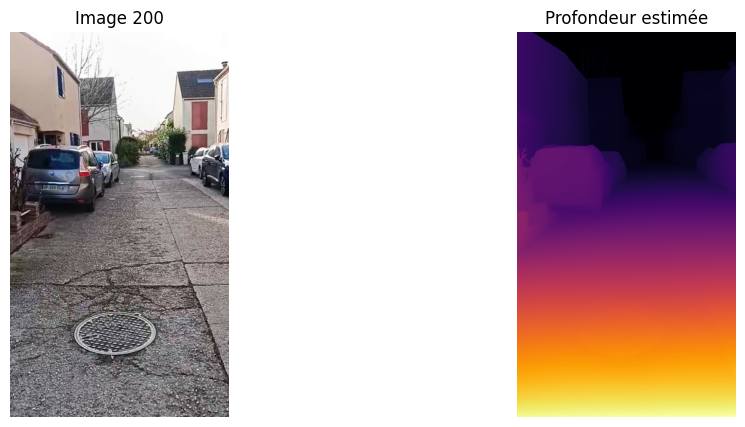

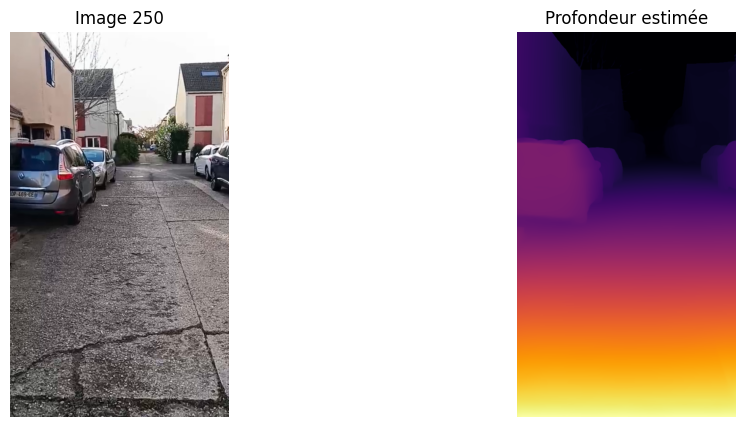

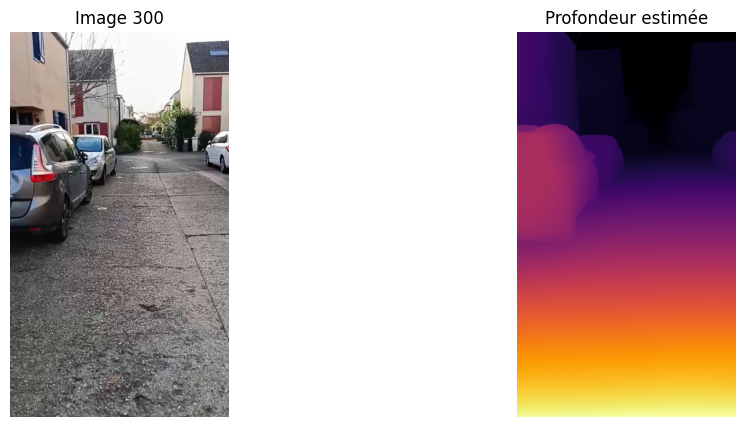

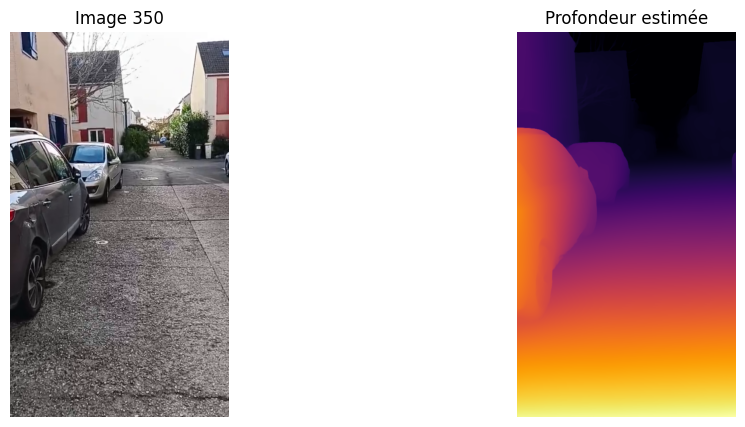

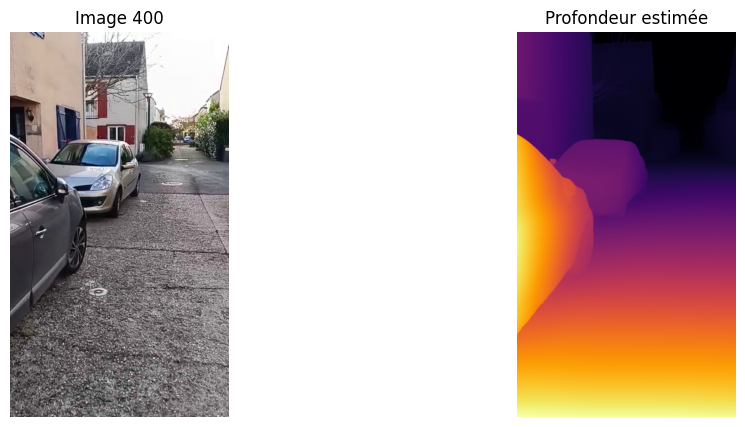

Nombre d'images traitées : 9


In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(video_path)

frame_count = 0
processed_count = 0

MAX_FRAMES = 30
FRAME_STEP = 50

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    if frame_count % FRAME_STEP == 0:

        # Réduction de la résolution pour accélérer les tests
        height, width = frame.shape[:2]

        new_width = 640
        new_height = int(height * new_width / width)

        frame = cv2.resize(
            frame,
            (new_width, new_height)
        )

        # Estimation de profondeur
        depth = model.infer_image(frame)

        # Affichage
        frame_rgb = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        plt.figure(figsize=(12, 5))

        plt.subplot(1, 2, 1)
        plt.imshow(frame_rgb)
        plt.title(f"Image {frame_count}")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(depth, cmap="inferno")
        plt.title("Profondeur estimée")
        plt.axis("off")

        plt.show()

        processed_count += 1

        # On se sert de cette image pour tester la suite (détection d'oobstacles)
        if frame_count == 400:
          image=frame_rgb
          cv2.imwrite("images/", image)

        if processed_count >= MAX_FRAMES:
            break

    frame_count += 1

cap.release()

print("Nombre d'images traitées :", processed_count)

Sauvegarde des cartes de profondeurs

In [10]:
import os

os.makedirs("depth_results", exist_ok=True)

cap = cv2.VideoCapture(video_path)

frame_id = 0

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    if frame_id % 50 == 0:

        depth = model.infer_image(frame)

        depth_normalized = cv2.normalize(
            depth,
            None,
            0,
            255,
            cv2.NORM_MINMAX
        )

        depth_normalized = depth_normalized.astype(np.uint8)

        output_path = f"depth_results/depth_{frame_id:50d}.png"

        cv2.imwrite(output_path, depth_normalized)

    frame_id += 1

cap.release()

print("Cartes de profondeur sauvegardées !")

Cartes de profondeur sauvegardées !


# Partie 2 : détection d'obstacles via rupture dans les cartes de profondeur

In [11]:
depth_map = np.asarray(depth, dtype=np.float32)

print("Dimensions :", depth_map.shape)
print("Valeur minimale :", np.min(depth_map))
print("Valeur maximale :", np.max(depth_map))
print("Moyenne :", np.mean(depth_map))

Dimensions : (848, 480)
Valeur minimale : 0.0
Valeur maximale : 9.034428
Moyenne : 3.9272344


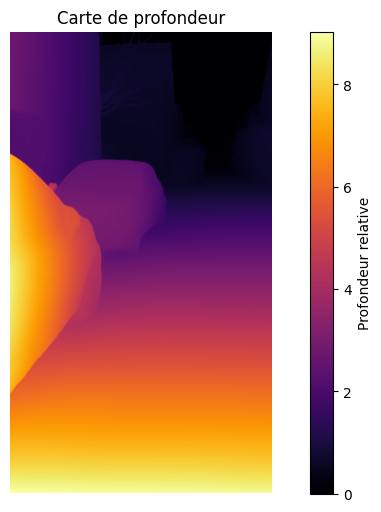

In [12]:
plt.figure(figsize=(10, 6))

plt.imshow(depth_map, cmap="inferno")
plt.colorbar(label="Profondeur relative")
plt.title("Carte de profondeur")
plt.axis("off")

plt.show()

Détection des ruptures de profondeur

calcul du gradient

In [13]:
# Lissage léger pour réduire le bruit
depth_smooth = cv2.GaussianBlur(
    depth_map,
    (5, 5),
    0
)

# Gradient horizontal
grad_x = cv2.Sobel(
    depth_smooth,
    cv2.CV_32F,
    1, 0,
    ksize=3
)

# Gradient vertical
grad_y = cv2.Sobel(
    depth_smooth,
    cv2.CV_32F,
    0, 1,
    ksize=3
)

# Intensité du gradient
gradient = np.sqrt(
    grad_x**2 + grad_y**2
)

visualisation

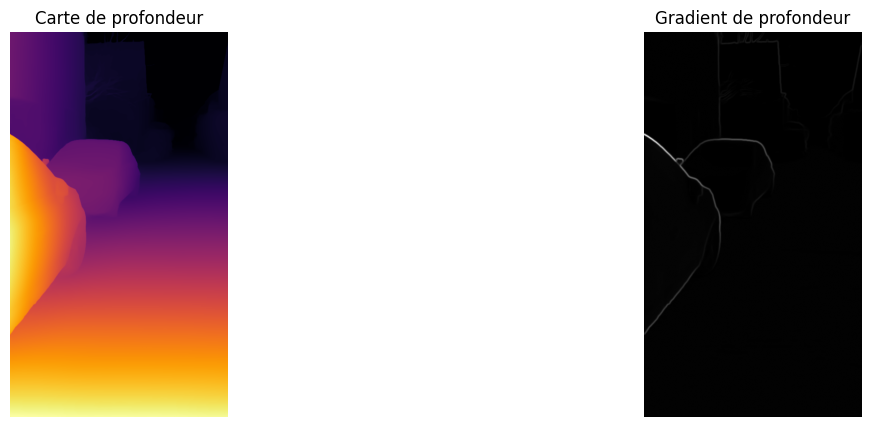

In [14]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.imshow(depth_map, cmap="inferno")
plt.title("Carte de profondeur")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gradient, cmap="gray")
plt.title("Gradient de profondeur")
plt.axis("off")

plt.show()

Application d'un masque pour détecter les rupture importantes

In [15]:
# On ignore les 35 % supérieurs de l'image
# pour commencer par les obstacles au niveau du sol.

h, w = gradient.shape

roi_start = int(h * 0.35)

gradient_roi = gradient[roi_start:, :]

threshold = np.percentile(
    gradient_roi,
    92
)

# Création du masque
obstacle_mask = np.zeros(
    (h, w),
    dtype=np.uint8
)

obstacle_mask[roi_start:, :] = (
    gradient_roi > threshold
).astype(np.uint8) * 255

print("Seuil utilisé :", threshold)

Seuil utilisé : 0.23319173


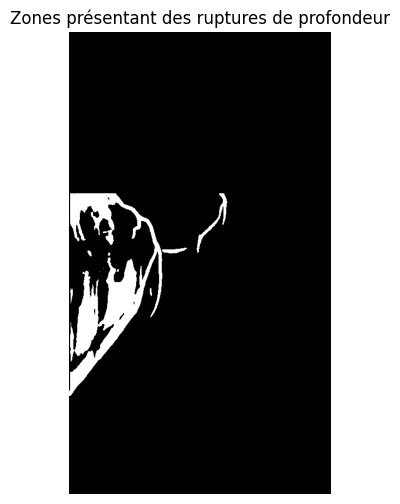

In [16]:
plt.figure(figsize=(12, 6))

plt.imshow(obstacle_mask, cmap="gray")
plt.title("Zones présentant des ruptures de profondeur")
plt.axis("off")

plt.show()

Regroupement des pixels en obstacles candidats

Epaississement des contours

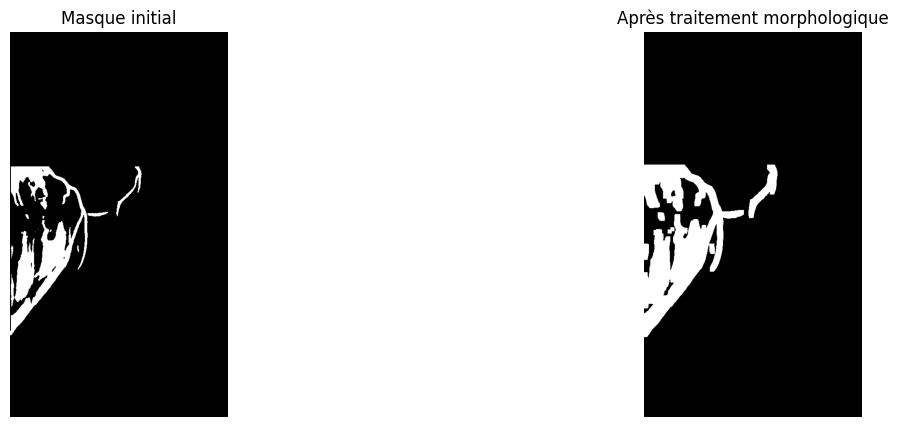

In [17]:
# Définition du noyau
kernel = np.ones((5, 5), np.uint8)

# Fermeture des petites discontinuités
closed_mask = cv2.morphologyEx(
    obstacle_mask,
    cv2.MORPH_CLOSE,
    kernel
)

# Dilatation
processed_mask = cv2.dilate(
    closed_mask,
    kernel,
    iterations=2
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.imshow(obstacle_mask, cmap="gray")
plt.title("Masque initial")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed_mask, cmap="gray")
plt.title("Après traitement morphologique")
plt.axis("off")

plt.show()

Détection des régions candidates

In [18]:
contours, hierarchy = cv2.findContours(
    processed_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

print("Nombre de régions détectées :", len(contours))

Nombre de régions détectées : 5


Elimination des régions trop petites

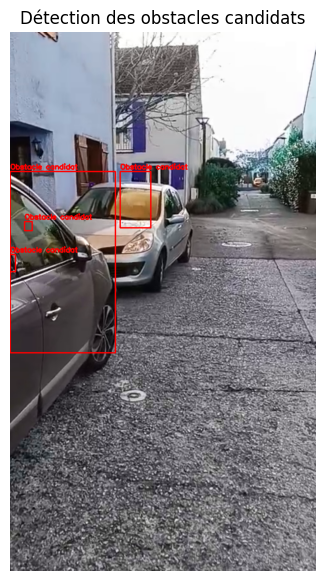

Nombre de régions retenues : 4


In [19]:
# Image originale
image_display = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

# Copie pour dessiner les résultats
result = image_display.copy()

MIN_AREA = 150

obstacles = []

for contour in contours:

    area = cv2.contourArea(contour)

    if area < MIN_AREA:
        continue

    x, y, w_box, h_box = cv2.boundingRect(contour)

    obstacles.append({
        "x": x,
        "y": y,
        "width": w_box,
        "height": h_box,
        "area": area
    })

    cv2.rectangle(
        result,
        (x, y),
        (x + w_box, y + h_box),
        (255, 0, 0),
        2
    )

    cv2.putText(
        result,
        "Obstacle candidat",
        (x, max(y - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 0, 0),
        2
    )

plt.figure(figsize=(12, 7))
plt.imshow(result)
plt.title("Détection des obstacles candidats")
plt.axis("off")
plt.show()

print("Nombre de régions retenues :", len(obstacles))

Distinction sol/obstacles

Visualisation d'une zone de sol potentielle

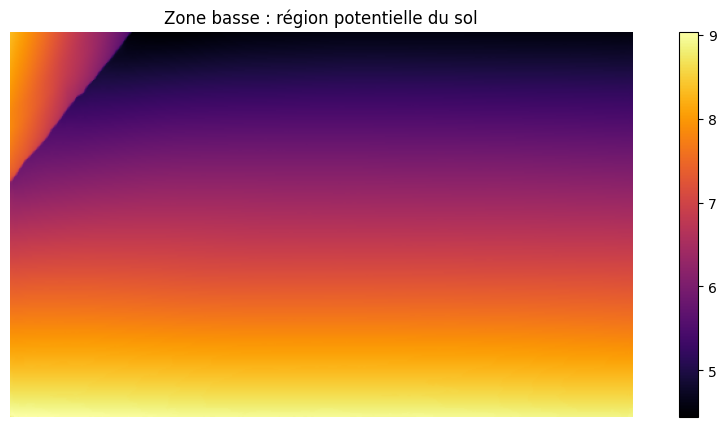

In [20]:
h, w = depth_map.shape

# Zone basse de l'image
ground_roi = depth_map[int(h * 0.65):, :]

plt.figure(figsize=(12, 5))

plt.imshow(ground_roi, cmap="inferno")
plt.title("Zone basse : région potentielle du sol")
plt.colorbar()
plt.axis("off")

plt.show()

Comparaison des profondeurs entre les régions

In [21]:
for obstacle in obstacles:

    x = obstacle["x"]
    y = obstacle["y"]
    box_w = obstacle["width"]
    box_h = obstacle["height"]

    # Profondeur moyenne de la région
    region = depth_map[y:y+box_h, x:x+box_w]

    # Zone de voisinage
    margin = 20

    x1 = max(0, x - margin)
    y1 = max(0, y - margin)
    x2 = min(depth_map.shape[1], x + box_w + margin)
    y2 = min(depth_map.shape[0], y + box_h + margin)

    neighborhood = depth_map[y1:y2, x1:x2]

    obstacle["depth_mean"] = float(np.mean(region))
    obstacle["depth_std"] = float(np.std(region))
    obstacle["neighbor_depth"] = float(np.mean(neighborhood))

    obstacle["depth_difference"] = (
        obstacle["depth_mean"] -
        obstacle["neighbor_depth"]
    )

for i, obstacle in enumerate(obstacles):

    print(
        f"Région {i+1} : "
        f"profondeur={obstacle['depth_mean']:.3f}, "
        f"différence locale={obstacle['depth_difference']:.3f}"
    )

Région 1 : profondeur=8.469, différence locale=0.293
Région 2 : profondeur=7.481, différence locale=0.027
Région 3 : profondeur=2.125, différence locale=-0.035
Région 4 : profondeur=5.435, différence locale=0.148


Fonction qui mélangent tout

In [22]:
def detect_obstacles(image, depth_map, min_area=150):

    h, w = depth_map.shape

    # 1. Lissage
    depth_smooth = cv2.GaussianBlur(
        depth_map, (5, 5), 0
    )

    # 2. Gradient
    grad_x = cv2.Sobel(
        depth_smooth, cv2.CV_32F, 1, 0, ksize=3
    )

    grad_y = cv2.Sobel(
        depth_smooth, cv2.CV_32F, 0, 1, ksize=3
    )

    gradient = np.sqrt(grad_x**2 + grad_y**2)

    # 3. Seuillage adaptatif
    roi_start = int(h * 0.35)

    threshold = np.percentile(
        gradient[roi_start:, :], 92
    )

    mask = np.zeros((h, w), dtype=np.uint8)

    mask[roi_start:, :] = (
        gradient[roi_start:, :] > threshold
    ).astype(np.uint8) * 255

    # 4. Morphologie
    kernel = np.ones((5, 5), np.uint8)

    mask = cv2.morphologyEx(
        mask, cv2.MORPH_CLOSE, kernel
    )

    mask = cv2.dilate(
        mask, kernel, iterations=2
    )

    # 5. Extraction des régions
    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    result = cv2.cvtColor(
        image.copy(),
        cv2.COLOR_BGR2RGB
    )

    candidates = []

    for contour in contours:

        area = cv2.contourArea(contour)

        if area < min_area:
            continue

        x, y, box_w, box_h = cv2.boundingRect(contour)

        candidates.append((x, y, box_w, box_h, area))

        cv2.rectangle(
            result,
            (x, y),
            (x + box_w, y + box_h),
            (255, 0, 0),
            2
        )

    return result, mask, candidates

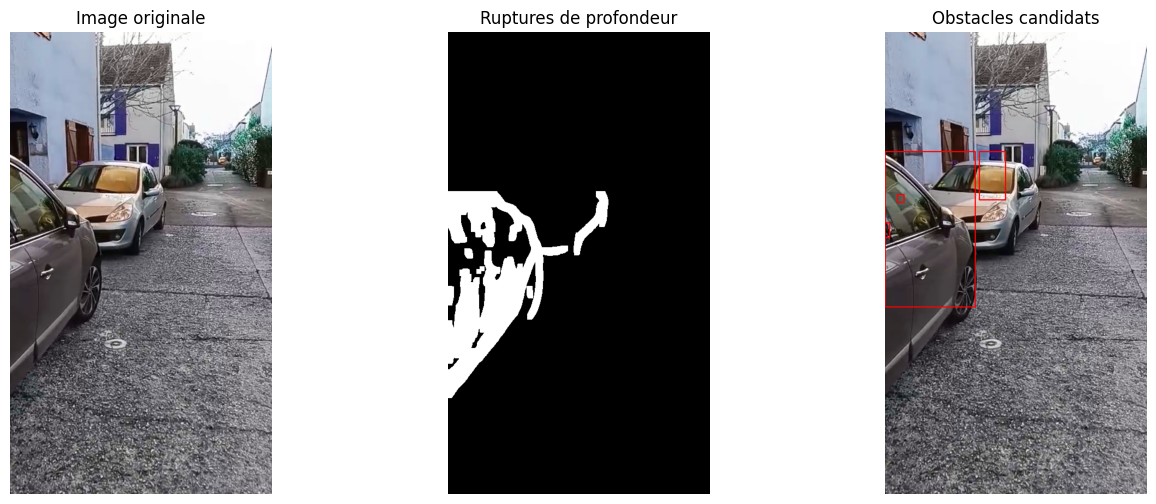

Nombre de candidats : 4


In [23]:
result, mask, candidates = detect_obstacles(
    image,
    depth_map
)

plt.figure(figsize=(16, 6))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Image originale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ruptures de profondeur")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(result)
plt.title("Obstacles candidats")
plt.axis("off")

plt.show()

print("Nombre de candidats :", len(candidates))